# III. Khám phá mối quan tâm của khách hàng thương mại điện tử

Notebook này triển khai **E-commerce Customer Behavior / Interest Discovery** bằng bộ dữ liệu review thương mại điện tử tiếng Việt.

Bộ dữ liệu chứa:

- nội dung đánh giá của khách hàng trong cột `Review`;
- 8 khía cạnh được gán nhãn:
  - `Price`
  - `Shipping`
  - `Outlook`
  - `Quality`
  - `Size`
  - `Shop_Service`
  - `General`
  - `Others`

Đây là bài toán **multi-label text classification** vì một review có thể đồng thời đề cập đến nhiều khía cạnh.

In [1]:
# Các thư viện chính

import os
import re
import time
import random
import joblib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    hamming_loss,
    jaccard_score,
    classification_report,
    multilabel_confusion_matrix,
    roc_auc_score
)

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

print("Đã khởi tạo môi trường.")
print("Random seed:", RANDOM_SEED)

Đã khởi tạo môi trường.
Random seed: 42


# 1. Định nghĩa bài toán

Bộ dữ liệu chứa các review của khách hàng về sản phẩm trên nền tảng thương mại điện tử.

Một review có thể đồng thời đề cập đến nhiều khía cạnh:

$$
A =
\{
Price,\ Shipping,\ Outlook,\ Quality,\ Size,\ Shop\_Service,\ General,\ Others
\}
$$

Do đó, không phù hợp nếu ép mỗi review chỉ có **một nhãn duy nhất**.

## Đầu vào

$$
X = \text{nội dung review của khách hàng}
$$

## Đầu ra

Với review thứ $i$, target là một vector multi-label:

$$
\mathbf{y}_i =
[y_{i1}, y_{i2}, \ldots, y_{i8}]
$$

Trong đó:

$$
y_{ij} =
\begin{cases}
1, & \text{review có đề cập đến khía cạnh } j \\
0, & \text{review không đề cập đến khía cạnh } j
\end{cases}
$$

Ví dụ:

```text
Review:
"Giao hàng nhanh, giày đẹp nhưng hơi chật"

Interest vector:
Price        = 0
Shipping     = 1
Outlook      = 1
Quality      = 0
Size         = 1
Shop_Service = 0
General      = 0
Others       = 0
```

Đây là bài toán **Supervised Multi-label Text Classification**.

## Mục tiêu ứng dụng

Kết quả có thể hỗ trợ doanh nghiệp:

- phát hiện khách hàng đang quan tâm đến yếu tố nào;
- tổng hợp chủ đề được nhắc đến nhiều;
- theo dõi vấn đề về vận chuyển, chất lượng, kích thước hoặc dịch vụ;
- hỗ trợ marketing và cải thiện sản phẩm;
- tự động phân loại số lượng lớn review.

# 2. Nguồn dữ liệu

**Dataset:** ABSA Vietnamese  
**Nguồn:** Kaggle  
**Kaggle URL:** https://www.kaggle.com/datasets/cthng123/absa-vietnamese

Dataset chuẩn hiện tại có:

- **11.700 observations**
- **9 columns**
- 1 cột văn bản: `Review`
- 8 cột annotation:
  - `Price`
  - `Shipping`
  - `Outlook`
  - `Quality`
  - `Size`
  - `Shop_Service`
  - `General`
  - `Others`

Các nhãn gốc có ý nghĩa:

| Giá trị | Ý nghĩa |
|---:|---|
| `-1` | Không đề cập đến aspect |
| `0` | Sentiment tiêu cực |
| `1` | Sentiment tích cực |
| `2` | Sentiment trung lập |

Để phù hợp với mục tiêu **Customer Interest Discovery**, target được chuyển thành:

$$
Mention(a) =
\begin{cases}
0, & label=-1 \\
1, & label\in\{0,1,2\}
\end{cases}
$$

Như vậy model dự đoán **khía cạnh mà khách hàng đề cập/quan tâm**, thay vì trực tiếp dự đoán polarity sentiment.

# 3. Tải dữ liệu

Dataset chuẩn được lưu bằng **UTF-8**, vì vậy có thể đọc trực tiếp bằng pandas và giữ nguyên tiếng Việt.

Ở bước này chưa tiến hành tiền xử lý. DataFrame gốc được giữ trong `df_raw` để các quyết định làm sạch sau đó có thể được kiểm tra và tái lập.

In [2]:
DATA_PATH = "ecommerce.csv"

if not os.path.exists(DATA_PATH):
    DATA_PATH = r'C:\Users\Dat\Downloads\PTHTTM\DATA\ecommerce.csv'

df_raw = pd.read_csv(
    DATA_PATH,
    encoding="utf-8"
)

print("Đã tải dataset thành công.")
print("Encoding: UTF-8")
print("Kích thước dữ liệu:", df_raw.shape)

display(df_raw.head())

Đã tải dataset thành công.
Encoding: UTF-8
Kích thước dữ liệu: (11700, 9)


,Review,Price,Shipping,Outlook,Quality,Size,Shop_Service,General,Others
0,"Giày đẹp, đi êm lắm",-1,-1,1,1,-1,-1,-1,-1
1,Mình săn sale với giá khá rẻ Chất lượng ok Shipper thân thiện Sẽ tiếp tục ủng hộ shop,1,1,-1,1,-1,-1,-1,-1
2,"Hình ảnh và video chỉ mang tính chất minh họa thôi. Về sản phẩm tính thang điểm thì 9/ 10 ạ, khá tốt hợp với giá tiề...",1,1,-1,-1,-1,-1,1,-1
3,Mình đặt size 39 nhưng chật k đeo nổi. Còn giầy thì đẹp giao hàng nhanh,-1,1,1,-1,0,-1,-1,-1
4,Nên mua nha mọi người đẹp xuất sắc lun ạ,-1,-1,1,-1,-1,-1,-1,-1


# 4. Kiểm tra và tìm hiểu dữ liệu

Các kiểm tra cơ bản theo yêu cầu Assignment:

- `df.shape`
- `df.head()`
- `df.info()`
- `df.describe()`
- `df.isna().sum()`
- `df.duplicated().sum()`

Ngoài ra, vì đây là dữ liệu text classification, cần kiểm tra thêm:

- số review khác nhau;
- số giá trị của từng nhãn;
- độ dài review;
- lỗi encoding;
- review trùng nội dung;
- mức độ mất cân bằng giữa các khía cạnh.

In [3]:
print("Shape:")
print(df_raw.shape)

print("\n5 dòng đầu:")
display(df_raw.head())

print("\nThông tin kiểu dữ liệu:")
df_raw.info()

print("\nThống kê mô tả:")
display(df_raw.describe(include="all").T)

print("\nGiá trị thiếu:")
display(df_raw.isna().sum().to_frame("so_luong_thieu"))

print("\nSố dòng trùng hoàn toàn:")
print(df_raw.duplicated().sum())

print("\nSố review có nội dung bị lặp:")
print(df_raw["Review"].duplicated().sum())

Shape:
(11700, 9)

5 dòng đầu:


,Review,Price,Shipping,Outlook,Quality,Size,Shop_Service,General,Others
0,"Giày đẹp, đi êm lắm",-1,-1,1,1,-1,-1,-1,-1
1,Mình săn sale với giá khá rẻ Chất lượng ok Shipper thân thiện Sẽ tiếp tục ủng hộ shop,1,1,-1,1,-1,-1,-1,-1
2,"Hình ảnh và video chỉ mang tính chất minh họa thôi. Về sản phẩm tính thang điểm thì 9/ 10 ạ, khá tốt hợp với giá tiề...",1,1,-1,-1,-1,-1,1,-1
3,Mình đặt size 39 nhưng chật k đeo nổi. Còn giầy thì đẹp giao hàng nhanh,-1,1,1,-1,0,-1,-1,-1
4,Nên mua nha mọi người đẹp xuất sắc lun ạ,-1,-1,1,-1,-1,-1,-1,-1



Thông tin kiểu dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 11700 entries, 0 to 11699
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Review        11700 non-null  str  
 1   Price         11700 non-null  int64
 2   Shipping      11700 non-null  int64
 3   Outlook       11700 non-null  int64
 4   Quality       11700 non-null  int64
 5   Size          11700 non-null  int64
 6   Shop_Service  11700 non-null  int64
 7   General       11700 non-null  int64
 8   Others        11700 non-null  int64
dtypes: int64(8), str(1)
memory usage: 2.1 MB

Thống kê mô tả:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Review,11700,11699,"Trời ơi săn được đôi quá đẹp luôn mà quá rẻ nữa, hơn cả mong đợi. Đế êm lắm mà tay mình ấn vào còn thây rén nữa. Màu...",2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,11700.0,NaN,NaN,NaN,-0.668718,0.813803,-1.0,-1.0,-1.0,-1.0,2.0
Shipping,11700.0,NaN,NaN,NaN,-0.430085,0.90169,-1.0,-1.0,-1.0,1.0,2.0
Outlook,11700.0,NaN,NaN,NaN,0.070085,1.016428,-1.0,-1.0,1.0,1.0,2.0
Quality,11700.0,NaN,NaN,NaN,-0.395897,0.972931,-1.0,-1.0,-1.0,1.0,2.0
Size,11700.0,NaN,NaN,NaN,-0.678718,0.776905,-1.0,-1.0,-1.0,-1.0,2.0
Shop_Service,11700.0,NaN,NaN,NaN,-0.522479,0.84164,-1.0,-1.0,-1.0,0.0,2.0
General,11700.0,NaN,NaN,NaN,-0.537179,0.962979,-1.0,-1.0,-1.0,-1.0,2.0
Others,11700.0,NaN,NaN,NaN,-0.76,0.813914,-1.0,-1.0,-1.0,-1.0,2.0



Giá trị thiếu:


,so_luong_thieu
Review,0
Price,0
Shipping,0
Outlook,0
Quality,0
Size,0
Shop_Service,0
General,0
Others,0



Số dòng trùng hoàn toàn:
1

Số review có nội dung bị lặp:
1


### Nhận xét ban đầu

Dataset có cấu trúc khác hai Application trước:

- không có các feature số về nhân khẩu học hoặc lịch sử giao dịch;
- feature chính là **văn bản `Review`**;
- 8 cột còn lại là annotation theo từng khía cạnh;
- một review có thể chứa nhiều khía cạnh cùng lúc.

Vì dataset không có behavioral/tabular customer features, notebook **không tạo giả các feature tabular** để ép theo đề.

Thay vào đó, phần biểu diễn tập trung đúng vào dữ liệu thực tế:

$$
	ext{Review}
ightarrow
	ext{Text Cleaning}
ightarrow
	ext{Tokens}
ightarrow
	ext{Vocabulary IDs}
ightarrow
	ext{TF-IDF Vector}
ightarrow
	ext{Multi-label Classifier}
$$

# 5. Phân tích chất lượng dữ liệu

Các vấn đề chất lượng cần xem xét:

1. missing review;
2. missing label;
3. dòng trùng hoàn toàn;
4. review giống nhau nhưng annotation khác nhau;
5. nhãn ngoài tập hợp hợp lệ `{-1, 0, 1, 2}`;
6. review không được gán bất kỳ khía cạnh nào;
7. lỗi encoding trong nội dung tiếng Việt;
8. class imbalance.

Với dữ liệu có annotation, không nên xóa review chỉ vì nội dung giống nhau nếu các nhãn khác nhau, vì đây có thể là:

- annotation inconsistency;
- các câu ngắn giống nhau trong nhiều ngữ cảnh;
- hoặc do lỗi encoding làm nhiều nội dung khác nhau trở nên giống nhau.

In [4]:
ASPECT_COLS = [
    "Price",
    "Shipping",
    "Outlook",
    "Quality",
    "Size",
    "Shop_Service",
    "General",
    "Others"
]

quality_table = pd.DataFrame({
    "kieu_du_lieu": df_raw.dtypes.astype(str),
    "so_luong_thieu": df_raw.isna().sum(),
    "so_gia_tri_khac_nhau": df_raw.nunique()
})

display(quality_table)

print("Dòng trùng hoàn toàn:", df_raw.duplicated().sum())
print("Review trùng nội dung:", df_raw["Review"].duplicated().sum())

,kieu_du_lieu,so_luong_thieu,so_gia_tri_khac_nhau
Review,str,0,11699
Price,int64,0,4
Shipping,int64,0,4
Outlook,int64,0,4
Quality,int64,0,4
Size,int64,0,4
Shop_Service,int64,0,4
General,int64,0,4
Others,int64,0,2


Dòng trùng hoàn toàn: 1
Review trùng nội dung: 1


In [5]:
# Kiểm tra review trùng nội dung nhưng nhãn khác nhau

duplicate_reviews = (
    df_raw[df_raw["Review"].duplicated(keep=False)]
    .sort_values("Review")
)

conflicting_groups = 0

for review, group in duplicate_reviews.groupby("Review"):
    if len(group[ASPECT_COLS].drop_duplicates()) > 1:
        conflicting_groups += 1

print("Số nhóm review trùng có annotation không giống nhau:", conflicting_groups)

display(duplicate_reviews.head(10))

Số nhóm review trùng có annotation không giống nhau: 0


,Review,Price,Shipping,Outlook,Quality,Size,Shop_Service,General,Others
2407,"Trời ơi săn được đôi quá đẹp luôn mà quá rẻ nữa, hơn cả mong đợi. Đế êm lắm mà tay mình ấn vào còn thây rén nữa. Màu...",1,-1,1,1,-1,-1,-1,-1
8008,"Trời ơi săn được đôi quá đẹp luôn mà quá rẻ nữa, hơn cả mong đợi. Đế êm lắm mà tay mình ấn vào còn thây rén nữa. Màu...",1,-1,1,1,-1,-1,-1,-1


### Quyết định về duplicate

- **Dòng trùng hoàn toàn:** xóa vì không cung cấp thêm thông tin.
- **Review giống nhau nhưng annotation khác:** không tự động xóa chỉ dựa vào text.

Lý do: xóa theo `Review` có thể làm mất annotation hoặc làm thay đổi phân bố nhãn.

Việc giữ lại các trường hợp này cũng giúp phản ánh một hạn chế thực tế của dữ liệu gán nhãn.

# 6. Phân tích giá trị thiếu

Cần kiểm tra riêng:

- review bị thiếu;
- nhãn khía cạnh bị thiếu;
- review rỗng hoặc chỉ chứa khoảng trắng.

Trong dữ liệu text, một review rỗng không thể tạo ra biểu diễn nội dung có ý nghĩa, vì vậy nếu tồn tại sẽ bị loại.

In [6]:
missing_table = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_percent": (df_raw.isna().mean() * 100).round(2)
})

display(missing_table)

empty_review_count = (
    df_raw["Review"]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
    .sum()
)

print("Review rỗng:", empty_review_count)

,missing_count,missing_percent
Review,0,0.0
Price,0,0.0
Shipping,0,0.0
Outlook,0,0.0
Quality,0,0.0
Size,0,0.0
Shop_Service,0,0.0
General,0,0.0
Others,0,0.0


Review rỗng: 0


### Quyết định xử lý missing

- Nếu `Review` bị thiếu/rỗng: loại quan sát vì không có input text.
- Nếu nhãn target bị thiếu: không thể dùng quan sát đó để huấn luyện có giám sát.
- Không dùng imputation kiểu median/mean cho text hay class label vì không có ý nghĩa ngữ nghĩa.

Với file hiện tại, kết quả thực tế được hiển thị ở cell trên.

# 7. Phân tích dữ liệu trùng lặp

Bước làm sạch duplicate chỉ loại **exact duplicates**.

Không dùng:

```python
drop_duplicates(subset=["Review"])
```

vì cùng một review text có thể xuất hiện với annotation khác nhau.

Sau khi xóa exact duplicate, cần kiểm tra lại shape để đảm bảo số lượng dữ liệu được thay đổi minh bạch.

In [7]:
df = df_raw.drop_duplicates().copy()

df = df[
    df["Review"].notna()
    & df["Review"].astype(str).str.strip().ne("")
].copy()

print("Shape ban đầu:", df_raw.shape)
print("Shape sau khi xóa exact duplicate và review rỗng:", df.shape)

Shape ban đầu: (11700, 9)
Shape sau khi xóa exact duplicate và review rỗng: (11699, 9)


# 8. Phân tích giá trị không hợp lệ

Theo cấu trúc dataset, tập nhãn hợp lệ là:

$$
L = \{-1,0,1,2\}
$$

Trong đó:

- `-1`: không đề cập;
- `0`: tiêu cực;
- `1`: tích cực;
- `2`: trung lập.

Cần kiểm tra:

1. có nhãn nào nằm ngoài tập hợp hợp lệ hay không;
2. có review nào cả 8 aspect đều bằng `-1` hay không.

Nếu toàn bộ 8 aspect đều bằng `-1`, target interest của observation là:

$$
\mathbf{y}_i =
[0,0,0,0,0,0,0,0]
$$

Đây vẫn là một **multi-label target hợp lệ**, nghĩa là review không đề cập đến bất kỳ aspect nào trong 8 nhóm được định nghĩa.

Vì vậy các observation này được **giữ lại**, không tự động coi là invalid data.

In [8]:
VALID_LABELS = {-1, 0, 1, 2}

invalid_label_report = {}

for col in ASPECT_COLS:
    invalid_count = (~df[col].isin(VALID_LABELS)).sum()
    invalid_label_report[col] = int(invalid_count)

display(
    pd.Series(
        invalid_label_report,
        name="so_luong_nhan_khong_hop_le"
    ).to_frame()
)

all_none_mask = (df[ASPECT_COLS] == -1).all(axis=1)

print("Số review không có bất kỳ aspect nào được gán:", all_none_mask.sum())

display(
    df.loc[
        all_none_mask,
        ["Review"] + ASPECT_COLS
    ].head(10)
)

,so_luong_nhan_khong_hop_le
Price,0
Shipping,0
Outlook,0
Quality,0
Size,0
Shop_Service,0
General,0
Others,0


Số review không có bất kỳ aspect nào được gán: 17


,Review,Price,Shipping,Outlook,Quality,Size,Shop_Service,General,Others
1033,Dép dẹp chất lượng cao cấp dày dặn rất đẹp,-1,-1,-1,-1,-1,-1,-1,-1
1919,"Với giá tiền này hàng như vậy là rất OK, trên cả tuyệt vời, mọi người nên mua, khuyên thật. Shop còn giao hàng rất n...",-1,-1,-1,-1,-1,-1,-1,-1
2363,"Giày đi êm, kiểu dáng hơi to một tý, cũng được 80% như hình , khá hài lòng",-1,-1,-1,-1,-1,-1,-1,-1
2460,"hình ảnh mang tính chất nhận xu, chủ shop tư vấn nhiệt tình",-1,-1,-1,-1,-1,-1,-1,-1
2574,"giày êm lắm nha, ichang ảnh mẫu, chọn đúng size là được ảnh chỉ mang tính chất minh họa",-1,-1,-1,-1,-1,-1,-1,-1
2599,Sản phẩm ok tiền nào của đấy sau ủng hộ tiếp 😁🥺🤪😜🥹😂☘️🎂😔😋,-1,-1,-1,-1,-1,-1,-1,-1
2636,Video và hình ảnh mang tính chất nhận xu. Còn giầy thì okla nhé,-1,-1,-1,-1,-1,-1,-1,-1
3069,Những câu nói của mình là fan cuồng mà kh có em bé này này cũng có vẻ đẹp riêng của nó,-1,-1,-1,-1,-1,-1,-1,-1
3131,Giầy đẹp lắm.,-1,-1,-1,-1,-1,-1,-1,-1
4711,"Mẫu giày Thể Thao 2 Dây Kép Sneaker Nữ Phong Cách Hàn Quốc - chuẩn hàng Quảng châu đủ hộp. - Thiết kế 2 dây kép, đan...",-1,-1,-1,-1,-1,-1,-1,-1


### Quyết định xử lý invalid value

- Nhãn ngoài `{-1, 0, 1, 2}` → cần loại hoặc quay lại nguồn dữ liệu để xác minh.
- `-1` → giá trị hợp lệ, biểu thị aspect không được đề cập.
- Review có cả 8 nhãn bằng `-1` → được giữ lại với target multi-label toàn số 0.

Cách xử lý này tránh xóa một negative observation hợp lệ của bài toán interest discovery.

In [9]:
# Không xóa các review có target toàn số 0.
# Đây vẫn là observation hợp lệ trong multi-label classification.

print(
    "Shape dữ liệu sau bước invalid-value analysis:",
    df.shape
)

print(
    "Số review có target toàn số 0 được giữ lại:",
    all_none_mask.sum()
)

Shape dữ liệu sau bước invalid-value analysis: (11699, 9)
Số review có target toàn số 0 được giữ lại: 17


# 9. Phân tích outlier

Với dữ liệu text, khái niệm outlier khác dữ liệu số.

Một đặc trưng quan trọng là **độ dài review**:

- review rất ngắn có thể thiếu ngữ cảnh;
- review rất dài có thể chứa quảng cáo, mô tả sản phẩm hoặc nội dung ngoài chủ đề.

Tuy nhiên, không nên tự động xóa review dài chỉ vì vượt IQR.

Ta sử dụng độ dài theo số từ để:

1. phát hiện review cực ngắn/cực dài;
2. kiểm tra phân bố;
3. quyết định có cần giới hạn biểu diễn hay không.

In [10]:
df["review_word_count"] = (
    df["Review"]
    .astype(str)
    .str.split()
    .str.len()
)

display(df["review_word_count"].describe().to_frame().T)

q1 = df["review_word_count"].quantile(0.25)
q3 = df["review_word_count"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_length_mask = (
    (df["review_word_count"] < lower_bound)
    | (df["review_word_count"] > upper_bound)
)

print("Ngưỡng IQR trên:", upper_bound)
print("Số review bị IQR đánh dấu về độ dài:", outlier_length_mask.sum())

display(
    df.loc[
        outlier_length_mask,
        ["Review", "review_word_count"]
    ]
    .sort_values("review_word_count", ascending=False)
    .head(10)
)

,count,mean,std,min,25%,50%,75%,max
review_word_count,11699.0,20.729208,20.716752,1.0,12.0,17.0,24.0,692.0


Ngưỡng IQR trên: 42.0
Số review bị IQR đánh dấu về độ dài: 730


,Review,review_word_count
5310,"🍉🍉🍉 1: ""Chuyện tốt thành đôi"" của Huỳnh Hiểu Minh và Trương Tiểu Phỉ là do anh ấy chủ động nhường phiên. Hiện tại nh...",692
6994,"CÓ NHỮNG CÂU NÓI NÀO TỪNG LÀM BẠN PHẢI SUY NGHĨ RẤT NHIỀU? 1. Có một ngày, tôi đối xử với bạn theo cách mà bạn vẫn t...",585
8054,NHỮNG NGUYÊN TẮC PHẢI NHỚ KHI SỐNG TẬP THỂ 1. Giữ im lặng khi người khác ngủ là quy tắc cơ bản nhất. 2. Nhờ bạn cùng...,479
1133,"Tôi hét khô cả họng mà ông ấy cứ như người khiếm thính vậy. Ông ta quay đầu lại nhìn tôi lắc đầu cười . Bữa cơm đó ,...",466
1586,💥💥 [CHÍNH THỨC CÓ MẶT TẠI TGSF] 💥💥 TƯƠI MỚI NGỌT NGÀO - NỔI BẬT HOÀN HẢO với BẢNG PHẤN MẮT &amp; MÁ ĐA NĂNG 7 Ô MÀU ...,389
11521,Vũ khí hạt nhân từng là biểu tượng cho sức mạnh quân sự và sức mạnh quốc gia. Việc thử nghiệm vũ khí hạt nhân thường...,374
10310,📣📣📣 ĐĂNG KÝ NGAY ĐỂ TRỞ THÀNH SINH VIÊN CỦA NGÔI TRƯỜNG UY TÍN 🏆 🥇🥈🥉 --‐‐-------------------------------------------...,369
11614,"Xung quanh ta rất còn nhiều người tử tế. Chỉ một sự nhầm lẫn mà mình suýt bị nhỡ chuyến xe về ICHOON, may là mình th...",347
7265,"rất kkkiudkopXã hội hiện đại luôn không ngừng phát triển, và sự xuất hiện của Internet đã mở ra một kỉ nguyên hoàn t...",339
10298,"★ ĐỌC NHANH CÙNG K CRUSH! ★ 🗳️ IU quyên góp 300 triệu won cho Trung tâm Y tế Châu Á ở Seoul, Hiệp hội Phúc lợi Trẻ e...",331


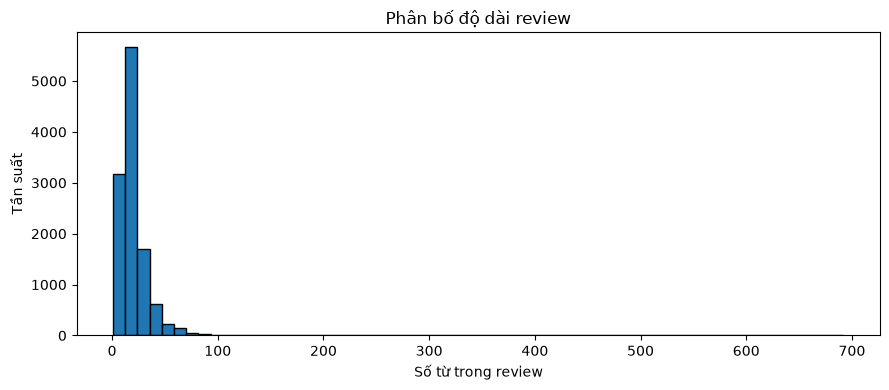

In [11]:
plt.figure(figsize=(9, 4))
plt.hist(df["review_word_count"], bins=60, edgecolor="black")
plt.xlabel("Số từ trong review")
plt.ylabel("Tần suất")
plt.title("Phân bố độ dài review")
plt.tight_layout()
plt.show()

### Quyết định về outlier text

Không xóa review dài một cách tự động.

Lý do:

- một review dài vẫn có thể chứa thông tin thật;
- TF-IDF có cơ chế chuẩn hóa trọng số;
- việc cắt bỏ review dài có thể làm mất các aspect được đề cập ở cuối câu.

Các review cực dài sẽ được xem xét trong **Error Analysis** để kiểm tra xem chúng có gây khó khăn cho mô hình hay không.

# 10. Phân tích khám phá dữ liệu (EDA)

Đối với Application 3, đề yêu cầu phân tích thêm:

- hành vi/khía cạnh được khách hàng đề cập;
- tần suất interest;
- đặc điểm comment/review;
- từ khóa phổ biến;
- class imbalance.

Mỗi biểu đồ quan trọng được diễn giải theo:

1. **Observation**
2. **Interpretation**
3. **ML implication**

,so_review_de_cap,ty_le_percent
Outlook,6338,54.18
Shipping,3526,30.14
Quality,3486,29.80
Shop_Service,3059,26.15
General,2311,19.75
Size,1975,16.88
Price,1729,14.78
Others,936,8.00


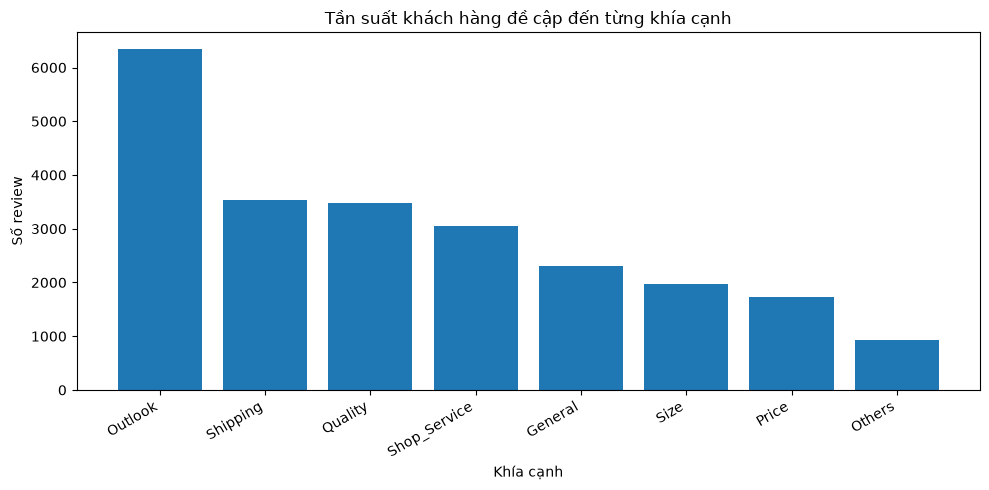

In [12]:
# Tần suất mỗi khía cạnh được đề cập

aspect_mentions = pd.Series({
    col: int((df[col] != -1).sum())
    for col in ASPECT_COLS
}).sort_values(ascending=False)

aspect_mention_pct = (
    aspect_mentions / len(df) * 100
).round(2)

aspect_frequency = pd.DataFrame({
    "so_review_de_cap": aspect_mentions,
    "ty_le_percent": aspect_mention_pct
})

display(aspect_frequency)

plt.figure(figsize=(10, 5))
plt.bar(aspect_frequency.index, aspect_frequency["so_review_de_cap"])
plt.ylabel("Số review")
plt.xlabel("Khía cạnh")
plt.title("Tần suất khách hàng đề cập đến từng khía cạnh")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### EDA 1 - Tần suất interest

**Observation:** Một số khía cạnh được đề cập nhiều hơn đáng kể so với các khía cạnh khác.

**Interpretation:** Mức độ quan tâm của khách hàng không phân bố đều. Các yếu tố như ngoại hình, vận chuyển hoặc chất lượng có thể xuất hiện thường xuyên hơn các khía cạnh hiếm.

**ML implication:** Đây là dấu hiệu **class imbalance** trong bài toán multi-label. Accuracy đơn thuần có thể gây hiểu nhầm, vì mô hình có thể đạt kết quả cao cho nhãn hiếm bằng cách dự đoán phần lớn là 0. Do đó cần dùng Precision, Recall và F1.

,so_review
num_aspects_mentioned,
0,17
1,4107
2,4275
3,2593
4,615
5,88
6,4


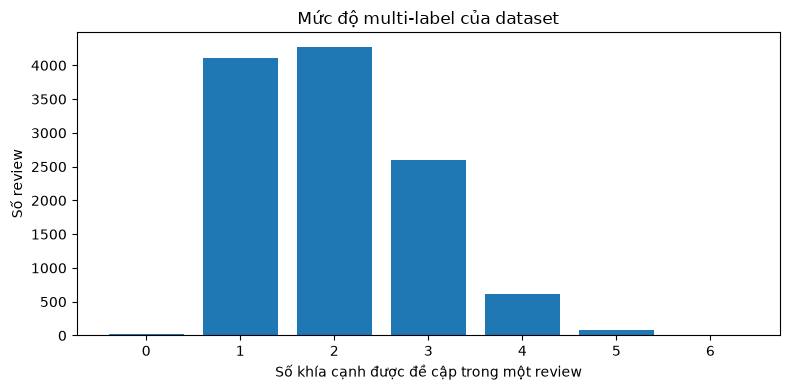

In [13]:
# Số aspect được đề cập trong mỗi review

df["num_aspects_mentioned"] = (
    df[ASPECT_COLS] != -1
).sum(axis=1)

aspect_count_distribution = (
    df["num_aspects_mentioned"]
    .value_counts()
    .sort_index()
)

display(
    aspect_count_distribution
    .rename("so_review")
    .to_frame()
)

plt.figure(figsize=(8, 4))
plt.bar(
    aspect_count_distribution.index.astype(str),
    aspect_count_distribution.values
)
plt.xlabel("Số khía cạnh được đề cập trong một review")
plt.ylabel("Số review")
plt.title("Mức độ multi-label của dataset")
plt.tight_layout()
plt.show()

### EDA 2 - Một review có bao nhiêu interest?

**Observation:** Nhiều review đề cập đồng thời từ hai khía cạnh trở lên.

**Interpretation:** Bài toán có bản chất multi-label thực sự. Việc ép dữ liệu thành single-class sẽ làm mất thông tin.

**ML implication:** Target phải có dạng ma trận:

$$
Y \in \{0,1\}^{N	imes8}
$$

thay vì một vector class đơn:

$$
y \in \{1,2,...,K\}^{N}
$$

,Không đề cập,Tiêu cực,Tích cực,Trung lập
Price,9970.0,16.0,1281.0,432.0
Shipping,8173.0,564.0,2782.0,180.0
Outlook,5361.0,459.0,5578.0,301.0
Quality,8213.0,463.0,2466.0,557.0
Size,9724.0,662.0,842.0,471.0
Shop_Service,8640.0,687.0,2216.0,156.0
General,9388.0,73.0,1372.0,866.0
Others,10763.0,0.0,0.0,936.0


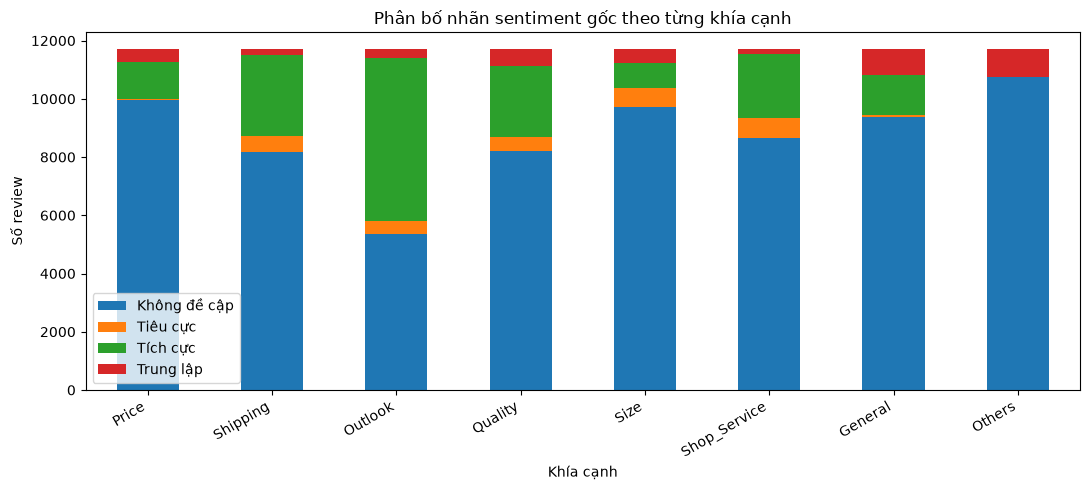

In [14]:
# Phân bố sentiment gốc theo từng aspect

label_names = {
    -1: "Không đề cập",
    0: "Tiêu cực",
    1: "Tích cực",
    2: "Trung lập"
}

sentiment_counts = pd.DataFrame({
    col: df[col].value_counts()
    for col in ASPECT_COLS
}).fillna(0).T

sentiment_counts = sentiment_counts.reindex(
    columns=[-1, 0, 1, 2],
    fill_value=0
)

sentiment_counts.columns = [
    label_names[x] for x in sentiment_counts.columns
]

display(sentiment_counts)

sentiment_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 5)
)

plt.ylabel("Số review")
plt.xlabel("Khía cạnh")
plt.title("Phân bố nhãn sentiment gốc theo từng khía cạnh")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### EDA 3 - Phân bố sentiment gốc

**Observation:** Các aspect không chỉ mất cân bằng về việc có/không được đề cập mà còn mất cân bằng giữa positive, negative và neutral.

**Interpretation:** Dataset ban đầu hỗ trợ bài toán Aspect-Based Sentiment Analysis (ABSA). Tuy nhiên notebook hiện tại tập trung vào **interest detection**, nên chỉ dùng thông tin “aspect có được đề cập hay không”.

**ML implication:** Khi chuyển target từ 4 trạng thái sang binary mention/no-mention, polarity sentiment bị mất khỏi target. Đây là một **information loss có chủ đích** để tạo bài toán phù hợp với mục tiêu customer-interest discovery.

,Price,Shipping,Outlook,Quality,Size,Shop_Service,General,Others
Price,1729,531,1148,654,228,354,212,0
Shipping,531,3526,1997,1069,545,1355,554,2
Outlook,1148,1997,6338,1860,1171,1606,518,1
Quality,654,1069,1860,3486,533,806,344,1
Size,228,545,1171,533,1975,454,236,1
Shop_Service,354,1355,1606,806,454,3059,502,1
General,212,554,518,344,236,502,2311,1
Others,0,2,1,1,1,1,1,936


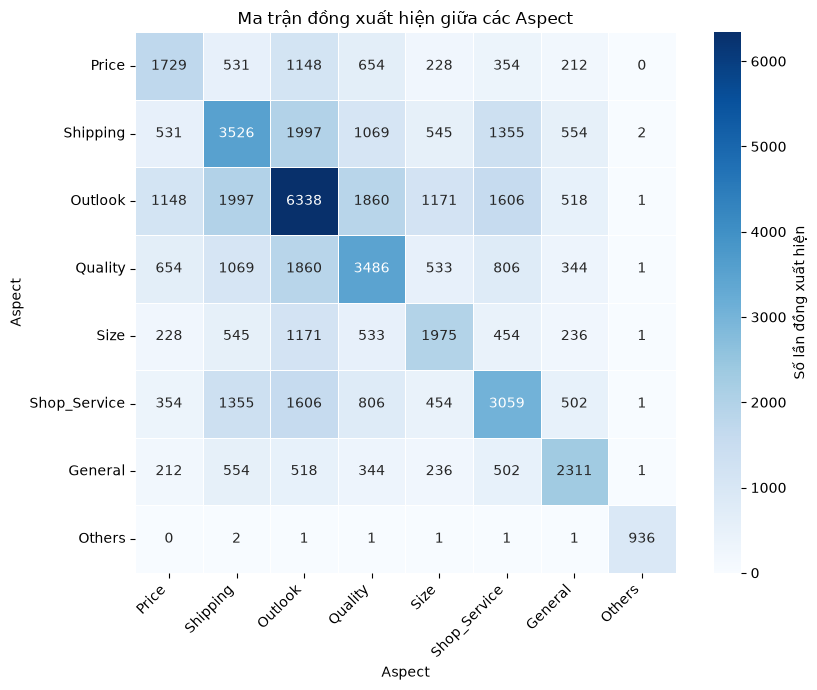

In [38]:
# Ma trận đồng xuất hiện giữa các aspect

import seaborn as sns
import matplotlib.pyplot as plt

mention_matrix = (df[ASPECT_COLS] != -1).astype(int)

cooccurrence = mention_matrix.T.dot(mention_matrix)

display(cooccurrence)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cooccurrence,
    annot=True,          # Hiển thị số trong từng ô
    fmt="d",             # Hiển thị số nguyên
    cmap="Blues",        # Màu heatmap
    linewidths=0.5,      # Đường kẻ giữa các ô
    square=True,
    cbar_kws={"label": "Số lần đồng xuất hiện"}
)

plt.title("Ma trận đồng xuất hiện giữa các Aspect")
plt.xlabel("Aspect")
plt.ylabel("Aspect")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### EDA 4 - Co-occurrence giữa các interest

**Observation:** Một số cặp aspect thường xuất hiện cùng nhau trong cùng review.

**Interpretation:** Mối quan tâm của khách hàng có thể có quan hệ phụ thuộc, ví dụ khách hàng vừa nói về ngoại hình vừa nói về chất lượng hoặc size.

**ML implication:** Multi-label classification phù hợp hơn việc huấn luyện một single-class classifier. Ngoài ra, một hạn chế của One-vs-Rest là mỗi label được học tương đối độc lập, nên quan hệ giữa các label chưa được mô hình hóa trực tiếp.

# 11. Các loại đặc trưng

## Input feature

### `Review`

- kiểu dữ liệu: text/string;
- đại diện cho nội dung đánh giá của khách hàng;
- cần chuyển thành biểu diễn số trước khi đưa vào model.

## Annotation / target gốc

8 cột:

```text
Price
Shipping
Outlook
Quality
Size
Shop_Service
General
Others
```

Giá trị:

```text
-1 = không đề cập
 0 = tiêu cực
 1 = tích cực
 2 = trung lập
```

## Target của bài toán interest discovery

Mỗi cột aspect được chuyển thành binary:

```text
label == -1  → 0
label != -1  → 1
```

Vì vậy:

$$
Y \in \{0,1\}^{N	imes8}
$$

Dataset **không có customer demographic/transaction tabular features** như age, sessions, purchase frequency hay cart actions.

# 12. Biểu diễn dữ liệu

Đây là phần trung tâm liên quan đến **Lecture 02 — Data Representation**.

## 12.1. Dữ liệu thô

Một observation ban đầu có dạng:

```text
Review = "Giày đẹp, đi êm lắm"

Price        = -1
Shipping     = -1
Outlook      = 1
Quality      = 1
Size         = -1
Shop_Service = -1
General      = -1
Others       = -1
```

Máy học không xử lý trực tiếp ý nghĩa ngôn ngữ của chuỗi ký tự. Text cần được chuyển thành biểu diễn số.

## 12.2. Clean Representation

Quy trình làm sạch nhẹ:

$$
\text{Raw Review}
\rightarrow
\text{chuẩn hóa khoảng trắng}
\rightarrow
\text{Clean Review}
$$

Dấu tiếng Việt được giữ nguyên vì chứa thông tin ngôn ngữ quan trọng.

## 12.3. Tokenization

Ví dụ:

```text
"giao hàng nhanh"
        ↓
["giao", "hàng", "nhanh"]
```

Khi dùng unigram + bigram, representation còn có thể chứa:

```text
"giao hàng"
"hàng nhanh"
```

## 12.4. Vocabulary IDs

Sau khi `TfidfVectorizer` được fit trên **training set**, mỗi token/ngram có một index trong vocabulary:

```text
"giao"       → vocabulary ID
"hàng"       → vocabulary ID
"giao hàng"  → vocabulary ID
```

Các ID này chỉ là vị trí trong feature space.

## 12.5. TF-IDF Vector

Mỗi review trở thành một vector số:

$$
\mathbf{x}_i =
[x_{i1},x_{i2},\ldots,x_{id}]
$$

Toàn bộ input trở thành:

$$
X \in \mathbb{R}^{N\times d}
$$

Trong đó:

- $N$: số review;
- $d$: kích thước vocabulary sau TF-IDF.

Đây là **sparse feature matrix**.

## 12.6. Target Representation

Mỗi review có target:

$$
\mathbf{y}_i =
[y_{i1},y_{i2},\ldots,y_{i8}]
$$

Toàn bộ target:

$$
Y \in \{0,1\}^{N\times8}
$$

Trong đó 8 cột lần lượt tương ứng với:

$$
[
Price,\ Shipping,\ Outlook,\ Quality,\ Size,\ Shop\_Service,\ General,\ Others
]
$$

## 12.7. Complete Text Representation Pipeline

$$
\text{Raw Customer Review}
\rightarrow
\text{Text Cleaning}
\rightarrow
\text{Tokens / N-grams}
\rightarrow
\text{Vocabulary IDs}
\rightarrow
\text{TF-IDF Vector}
\rightarrow
\text{Multi-label Model}
\rightarrow
\text{Predicted Interests}
$$

# 13. Feature Engineering

Feature engineering cho dữ liệu text gồm:

1. loại khoảng trắng thừa;
2. chuẩn hóa khoảng trắng giữa các từ;
3. giữ nguyên dấu tiếng Việt;
4. lowercase trong `TfidfVectorizer`;
5. sử dụng unigram + bigram;
6. chuyển 8 annotation gốc thành binary interest labels.

In [16]:
def clean_review(text):
    text = str(text).strip()

    # Loại URL nếu có
    text = re.sub(
        r"http\S+|www\.\S+",
        " ",
        text
    )

    # Chuẩn hóa khoảng trắng
    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text


df["Review_clean"] = (
    df["Review"]
    .map(clean_review)
)

# 1 = aspect được đề cập
# 0 = aspect không được đề cập
Y = (
    df[ASPECT_COLS]
    .ne(-1)
    .astype(int)
)

X_text = (
    df["Review_clean"]
    .copy()
)

print("Số review:", len(X_text))
print("X shape:", X_text.shape)
print("Y shape:", Y.shape)

display(
    pd.DataFrame({
        "Review_raw":
            df["Review"].head(5),

        "Review_clean":
            df["Review_clean"].head(5)
    })
)

Số review: 11699
X shape: (11699,)
Y shape: (11699, 8)


,Review_raw,Review_clean
0,"Giày đẹp, đi êm lắm","Giày đẹp, đi êm lắm"
1,Mình săn sale với giá khá rẻ Chất lượng ok Shipper thân thiện Sẽ tiếp tục ủng hộ shop,Mình săn sale với giá khá rẻ Chất lượng ok Shipper thân thiện Sẽ tiếp tục ủng hộ shop
2,"Hình ảnh và video chỉ mang tính chất minh họa thôi. Về sản phẩm tính thang điểm thì 9/ 10 ạ, khá tốt hợp với giá tiề...","Hình ảnh và video chỉ mang tính chất minh họa thôi. Về sản phẩm tính thang điểm thì 9/ 10 ạ, khá tốt hợp với giá tiề..."
3,Mình đặt size 39 nhưng chật k đeo nổi. Còn giầy thì đẹp giao hàng nhanh,Mình đặt size 39 nhưng chật k đeo nổi. Còn giầy thì đẹp giao hàng nhanh
4,Nên mua nha mọi người đẹp xuất sắc lun ạ,Nên mua nha mọi người đẹp xuất sắc lun ạ


In [17]:
# Kiểm tra chất lượng Unicode của file chuẩn

replacement_character_count = (
    df["Review"]
    .astype(str)
    .str.contains(
        "�",
        regex=False
    )
    .sum()
)

mojibake_count = (
    df["Review"]
    .astype(str)
    .str.contains(
        "ï¿½",
        regex=False
    )
    .sum()
)

print(
    "Review chứa Unicode replacement character (�):",
    replacement_character_count
)

print(
    "Review chứa mojibake 'ï¿½':",
    mojibake_count
)

print("\nVí dụ review tiếng Việt:")
display(
    df[["Review"]]
    .head(5)
)

Review chứa Unicode replacement character (�): 0
Review chứa mojibake 'ï¿½': 0

Ví dụ review tiếng Việt:


,Review
0,"Giày đẹp, đi êm lắm"
1,Mình săn sale với giá khá rẻ Chất lượng ok Shipper thân thiện Sẽ tiếp tục ủng hộ shop
2,"Hình ảnh và video chỉ mang tính chất minh họa thôi. Về sản phẩm tính thang điểm thì 9/ 10 ạ, khá tốt hợp với giá tiề..."
3,Mình đặt size 39 nhưng chật k đeo nổi. Còn giầy thì đẹp giao hàng nhanh
4,Nên mua nha mọi người đẹp xuất sắc lun ạ


### Nhận xét về chất lượng văn bản

File `ecommerce.csv` chuẩn hiển thị tiếng Việt đúng UTF-8.

Điều này rất quan trọng đối với text representation vì:

- token tiếng Việt được giữ đúng;
- từ có dấu không bị biến thành ký tự lỗi;
- vocabulary phản ánh nội dung thực tế;
- TF-IDF không phải học các token mojibake vô nghĩa.

Notebook không tự động bỏ dấu tiếng Việt vì dấu có thể giúp phân biệt từ và giữ lại thông tin ngữ nghĩa.

# 14. Chia tập train / validation / test

Dữ liệu được chia thành:

- **70% training**
- **15% validation**
- **15% test**

Vai trò:

- training: fit TF-IDF và model;
- validation: so sánh 6 mô hình và chọn model tốt nhất;
- test: chỉ dùng một lần để đánh giá cuối cùng.

## Stratification

Đây là bài toán multi-label nên `train_test_split(stratify=Y)` không hỗ trợ trực tiếp như single-label classification.

Vì vậy notebook:

1. dùng random seed cố định;
2. chia ngẫu nhiên;
3. **kiểm tra tỷ lệ positive của từng aspect trên train/validation/test**.

Nếu các tỷ lệ gần nhau, split được xem là đủ ổn định cho thí nghiệm này.

Một phương án nâng cao hơn là sử dụng iterative multilabel stratification.

In [18]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X_text,
    Y,
    test_size=0.30,
    random_state=RANDOM_SEED
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_SEED
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

print("\nTỷ lệ:")
print("Train:", round(len(X_train) / len(X_text), 3))
print("Validation:", round(len(X_val) / len(X_text), 3))
print("Test:", round(len(X_test) / len(X_text), 3))

Train: (8189,) (8189, 8)
Validation: (1755,) (1755, 8)
Test: (1755,) (1755, 8)

Tỷ lệ:
Train: 0.7
Validation: 0.15
Test: 0.15


In [19]:
# Kiểm tra tỷ lệ positive của từng label sau split

split_prevalence = pd.DataFrame({
    "Train": y_train.mean(),
    "Validation": y_val.mean(),
    "Test": y_test.mean()
})

display(
    (split_prevalence * 100)
    .round(2)
    .rename_axis("Aspect")
)

,Train,Validation,Test
Aspect,,,
Price,14.79,13.16,16.35
Shipping,29.74,30.54,31.62
Outlook,54.12,52.99,55.61
Quality,29.74,31.05,28.83
Size,16.36,17.49,18.69
Shop_Service,26.10,27.07,25.47
General,19.86,19.43,19.60
Others,7.89,9.29,7.24


# 15. Pipeline tiền xử lý

Text representation sử dụng `TfidfVectorizer`.

Cấu hình:

- lowercase đã xử lý trước;
- unigram + bigram;
- `min_df=2` để bỏ token chỉ xuất hiện một lần;
- `max_df=0.98` để giảm token quá phổ biến;
- giới hạn vocabulary để kiểm soát độ phức tạp;
- `sublinear_tf=True` để giảm ảnh hưởng của tần suất rất lớn.

TF-IDF:

$$
TFIDF(t,d)
=
TF(t,d)
\times
IDF(t)
$$

Một token có trọng số cao khi:

- xuất hiện trong review hiện tại;
- nhưng không xuất hiện quá phổ biến trong toàn bộ corpus.

Quan trọng:

> `TfidfVectorizer` chỉ được fit trên training data.

Validation và test chỉ sử dụng `transform()` để tránh data leakage.

In [20]:
TFIDF_PARAMS = {
    "ngram_range": (1, 2),
    "max_features": 6000,
    "min_df": 2,
    "max_df": 0.98,
    "sublinear_tf": True
}

representation_vectorizer = TfidfVectorizer(
    **TFIDF_PARAMS
)

X_train_tfidf = representation_vectorizer.fit_transform(
    X_train
)

X_val_tfidf = representation_vectorizer.transform(
    X_val
)

print("Shape text ban đầu train:", X_train.shape)
print("Shape TF-IDF train:", X_train_tfidf.shape)
print("Shape TF-IDF validation:", X_val_tfidf.shape)
print("Data type:", X_train_tfidf.dtype)
print("Loại ma trận:", type(X_train_tfidf))

Shape text ban đầu train: (8189,)
Shape TF-IDF train: (8189, 6000)
Shape TF-IDF validation: (1755, 6000)
Data type: float64
Loại ma trận: <class 'scipy.sparse._csr.csr_matrix'>


In [21]:
# Minh họa: Review → Tokens → IDs → TF-IDF Vector

sample_text = X_train.iloc[0]

analyzer = representation_vectorizer.build_analyzer()
sample_tokens = analyzer(sample_text)

token_id_pairs = [
    (token, representation_vectorizer.vocabulary_.get(token))
    for token in sample_tokens
    if token in representation_vectorizer.vocabulary_
]

sample_vector = representation_vectorizer.transform(
    [sample_text]
)

nonzero_indices = sample_vector.nonzero()[1]
feature_names = representation_vectorizer.get_feature_names_out()

tfidf_values = [
    (
        feature_names[idx],
        idx,
        sample_vector[0, idx]
    )
    for idx in nonzero_indices
]

print("REVIEW:")
print(sample_text)

print("\nTOKENS / N-GRAMS đầu tiên:")
print(sample_tokens[:20])

print("\nTOKEN → VOCABULARY ID:")
print(token_id_pairs[:20])

print("\nTF-IDF VECTOR SHAPE:")
print(sample_vector.shape)

print("\nCác phần tử khác 0 đầu tiên:")
for item in tfidf_values[:20]:
    print(item)

REVIEW:
Hàng đẹp lắm nha hộp vẫn còn nguyên đc bảo vệ bởi 2 lớp hộp chắc chắn k ảnh hưởng đến form giày lần đầu mua giày trênn shopee mà ưng lắm luôn sẽ ủng hộ shop tiếp

TOKENS / N-GRAMS đầu tiên:
['hàng', 'đẹp', 'lắm', 'nha', 'hộp', 'vẫn', 'còn', 'nguyên', 'đc', 'bảo', 'vệ', 'bởi', 'lớp', 'hộp', 'chắc', 'chắn', 'ảnh', 'hưởng', 'đến', 'form']

TOKEN → VOCABULARY ID:
[('hàng', np.int64(1476)), ('đẹp', np.int64(5697)), ('lắm', np.int64(2356)), ('nha', np.int64(3011)), ('hộp', np.int64(1736)), ('vẫn', np.int64(5096)), ('còn', np.int64(685)), ('nguyên', np.int64(2955)), ('đc', np.int64(5386)), ('bảo', np.int64(229)), ('vệ', np.int64(5157)), ('bởi', np.int64(300)), ('lớp', np.int64(2425)), ('hộp', np.int64(1736)), ('chắc', np.int64(542)), ('chắn', np.int64(550)), ('ảnh', np.int64(5952)), ('hưởng', np.int64(1670)), ('đến', np.int64(5826)), ('form', np.int64(1082))]

TF-IDF VECTOR SHAPE:
(1, 6000)

Các phần tử khác 0 đầu tiên:
('bảo', np.int32(229), np.float64(0.1446191063432065))
('bảo vệ',

In [39]:
# =========================================
# HIỂN THỊ BẢNG TF-IDF CỦA SAMPLE REVIEW
# =========================================

tfidf_table = pd.DataFrame(
    tfidf_values,
    columns=[
        "Token / N-gram",
        "Vocabulary ID",
        "TF-IDF Score"
    ]
)

# Sắp xếp theo TF-IDF giảm dần
tfidf_table = (
    tfidf_table
    .sort_values(
        by="TF-IDF Score",
        ascending=False
    )
    .reset_index(drop=True)
)

print("=" * 70)
print("TF-IDF TABLE")
print("=" * 70)

display(
    tfidf_table.style.format({
        "TF-IDF Score": "{:.4f}"
    })
)

TF-IDF TABLE


,Token / N-gram,Vocabulary ID,TF-IDF Score
0,lớp hộp,2426,0.2129
1,mà ưng,2692,0.2063
2,bởi,300,0.1987
3,hưởng đến,1671,0.1946
4,còn nguyên,697,0.1895
5,luôn sẽ,2128,0.1895
6,shopee,4072,0.1839
7,vẫn còn,5100,0.1827
8,bảo vệ,230,0.1763
9,ảnh hưởng,5955,0.1745


### Biểu diễn cuối cùng

Nếu training set có $N_{train}$ review và vocabulary có $d$ token/ngram:

$$
X_{train}
\in
\mathbb{R}^{N_{train}\times d}
$$

Target:

$$
Y_{train}
\in
\{0,1\}^{N_{train}\times8}
$$

Ví dụ:

```text
Raw Review
    ↓
Clean Review
    ↓
Tokens / N-grams
    ↓
Vocabulary IDs
    ↓
TF-IDF Sparse Vector
    ↓
[x1, x2, ..., xd]
    ↓
Multi-label Model
    ↓
[Price, Shipping, ..., Others]
```

# 16. Mô hình cơ sở (Baseline)

Baseline được chọn là **Logistic Regression với One-vs-Rest**.

Trong multi-label classification, `OneVsRestClassifier` huấn luyện một binary classifier cho mỗi aspect:

```text
Classifier 1 → Price
Classifier 2 → Shipping
Classifier 3 → Outlook
...
Classifier 8 → Others
```

Mỗi classifier quyết định:

```text
0 = không đề cập
1 = có đề cập
```

`class_weight="balanced"` được sử dụng để giảm ảnh hưởng của class imbalance.

In [22]:
baseline_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(**TFIDF_PARAMS)
    ),
    (
        "model",
        OneVsRestClassifier(
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced"
            )
        )
    )
])

start = time.perf_counter()

baseline_pipeline.fit(
    X_train,
    y_train
)

baseline_time = time.perf_counter() - start

baseline_pred = baseline_pipeline.predict(
    X_val
)

baseline_metrics = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Subset Accuracy":
        accuracy_score(y_val, baseline_pred),

    "Precision Micro":
        precision_score(
            y_val,
            baseline_pred,
            average="micro",
            zero_division=0
        ),

    "Recall Micro":
        recall_score(
            y_val,
            baseline_pred,
            average="micro",
            zero_division=0
        ),

    "F1 Micro":
        f1_score(
            y_val,
            baseline_pred,
            average="micro",
            zero_division=0
        ),

    "F1 Macro":
        f1_score(
            y_val,
            baseline_pred,
            average="macro",
            zero_division=0
        ),

    "Hamming Loss":
        hamming_loss(y_val, baseline_pred),

    "Training Time (s)":
        baseline_time
}])

display(baseline_metrics)

,Model,Subset Accuracy,Precision Micro,Recall Micro,F1 Micro,F1 Macro,Hamming Loss,Training Time (s)
0,Logistic Regression,0.529345,0.81786,0.851474,0.834329,0.809523,0.084972,1.384191


# 17. Huấn luyện mô hình

Theo yêu cầu Application 3, notebook so sánh **6 mô hình**.

## 1. Logistic Regression

Linear classifier mạnh cho TF-IDF, dễ triển khai.

## 2. Decision Tree

Có khả năng học quan hệ phi tuyến, nhưng có nguy cơ overfitting với không gian text nhiều chiều.

## 3. Random Forest

Ensemble nhiều Decision Tree, thường ổn định hơn một cây đơn.

## 4. Linear SVM

Phù hợp với dữ liệu sparse high-dimensional như TF-IDF.

## 5. SGD Classifier

Text-based linear classifier huấn luyện nhanh, phù hợp với dữ liệu nhiều chiều.

## 6. Multinomial Naive Bayes

Mô hình truyền thống phổ biến cho text classification, nhanh và là một baseline bổ sung hợp lý.

Mỗi mô hình đều sử dụng cùng cấu hình TF-IDF để việc so sánh công bằng.

In [23]:
MODEL_ESTIMATORS = {
    "Logistic Regression":
        OneVsRestClassifier(
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced"
            )
        ),

    "Decision Tree":
        OneVsRestClassifier(
            DecisionTreeClassifier(
                max_depth=30,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=RANDOM_SEED
            )
        ),

    "Random Forest":
        OneVsRestClassifier(
            RandomForestClassifier(
                n_estimators=100,
                max_depth=30,
                min_samples_leaf=2,
                class_weight="balanced_subsample",
                random_state=RANDOM_SEED,
                n_jobs=-1
            )
        ),

    "Linear SVM":
        OneVsRestClassifier(
            LinearSVC(
                class_weight="balanced"
            )
        ),

    "SGD Text Classifier":
        OneVsRestClassifier(
            SGDClassifier(
                loss="log_loss",
                class_weight="balanced",
                max_iter=2000,
                random_state=RANDOM_SEED
            )
        ),

    "Multinomial Naive Bayes":
        OneVsRestClassifier(
            MultinomialNB(
                alpha=0.5
            )
        )
}

trained_models = {}
validation_rows = []

for name, estimator in MODEL_ESTIMATORS.items():

    pipeline = Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                **TFIDF_PARAMS
            )
        ),
        (
            "model",
            clone(estimator)
        )
    ])

    start = time.perf_counter()

    pipeline.fit(
        X_train,
        y_train
    )

    training_time = (
        time.perf_counter()
        - start
    )

    pred = pipeline.predict(
        X_val
    )

    row = {
        "Model": name,

        "Subset Accuracy":
            accuracy_score(
                y_val,
                pred
            ),

        "Precision Micro":
            precision_score(
                y_val,
                pred,
                average="micro",
                zero_division=0
            ),

        "Recall Micro":
            recall_score(
                y_val,
                pred,
                average="micro",
                zero_division=0
            ),

        "F1 Micro":
            f1_score(
                y_val,
                pred,
                average="micro",
                zero_division=0
            ),

        "F1 Macro":
            f1_score(
                y_val,
                pred,
                average="macro",
                zero_division=0
            ),

        "Hamming Loss":
            hamming_loss(
                y_val,
                pred
            ),

        "Jaccard Micro":
            jaccard_score(
                y_val,
                pred,
                average="micro",
                zero_division=0
            ),

        "Training Time (s)":
            training_time
    }

    validation_rows.append(row)

    trained_models[name] = pipeline

validation_results = (
    pd.DataFrame(validation_rows)
    .sort_values(
        "F1 Micro",
        ascending=False
    )
    .reset_index(drop=True)
)

display(validation_results)

,Model,Subset Accuracy,Precision Micro,Recall Micro,F1 Micro,F1 Macro,Hamming Loss,Jaccard Micro,Training Time (s)
0,SGD Text Classifier,0.531054,0.817490,0.853175,0.834951,0.810562,0.084758,0.716667,1.621335
1,Logistic Regression,0.529345,0.817860,0.851474,0.834329,0.809523,0.084972,0.715749,1.300906
2,Linear SVM,0.529915,0.824362,0.842120,0.833146,0.810826,0.084758,0.714011,1.741332
3,Random Forest,0.508832,0.834062,0.810658,0.822193,0.790042,0.088105,0.698072,8.463896
4,Decision Tree,0.434758,0.768765,0.827381,0.796997,0.761751,0.105912,0.662506,12.279803
5,Multinomial Naive Bayes,0.379487,0.822540,0.651644,0.727186,0.663541,0.122863,0.571322,1.231855


# 18. So sánh mô hình

## Vì sao không dùng Accuracy làm metric chính?

Trong multi-label classification, `accuracy_score` của scikit-learn là **subset accuracy**.

Một observation chỉ được tính là đúng khi **toàn bộ 8 nhãn đều đúng**.

Ví dụ:

```text
Actual:    [0,1,1,0,1,0,0,0]
Predicted: [0,1,1,0,0,0,0,0]
```

Mô hình đúng 7/8 label nhưng subset accuracy của observation này vẫn là 0.

Ngoài ra dataset bị class imbalance.

## Metric chính: Micro-F1

Micro-F1 tính tổng TP, FP, FN trên tất cả label trước khi tính F1.

Nó phù hợp khi mục tiêu là đánh giá khả năng phát hiện aspect trên toàn bộ dataset.

## Các metric báo cáo

- Subset Accuracy
- Precision Micro
- Recall Micro
- F1 Micro
- F1 Macro
- Hamming Loss
- Jaccard Micro
- Training Time

Mô hình được chọn dựa chủ yếu trên **validation Micro-F1**, đồng thời xem xét Macro-F1 và chi phí tính toán.

,Model,Subset Accuracy,Precision Micro,Recall Micro,F1 Micro,F1 Macro,Hamming Loss,Jaccard Micro,Training Time (s)
0,SGD Text Classifier,0.5311,0.8175,0.8532,0.8350,0.8106,0.0848,0.7167,1.621
1,Logistic Regression,0.5293,0.8179,0.8515,0.8343,0.8095,0.0850,0.7157,1.301
2,Linear SVM,0.5299,0.8244,0.8421,0.8331,0.8108,0.0848,0.7140,1.741
3,Random Forest,0.5088,0.8341,0.8107,0.8222,0.7900,0.0881,0.6981,8.464
4,Decision Tree,0.4348,0.7688,0.8274,0.7970,0.7618,0.1059,0.6625,12.280
5,Multinomial Naive Bayes,0.3795,0.8225,0.6516,0.7272,0.6635,0.1229,0.5713,1.232


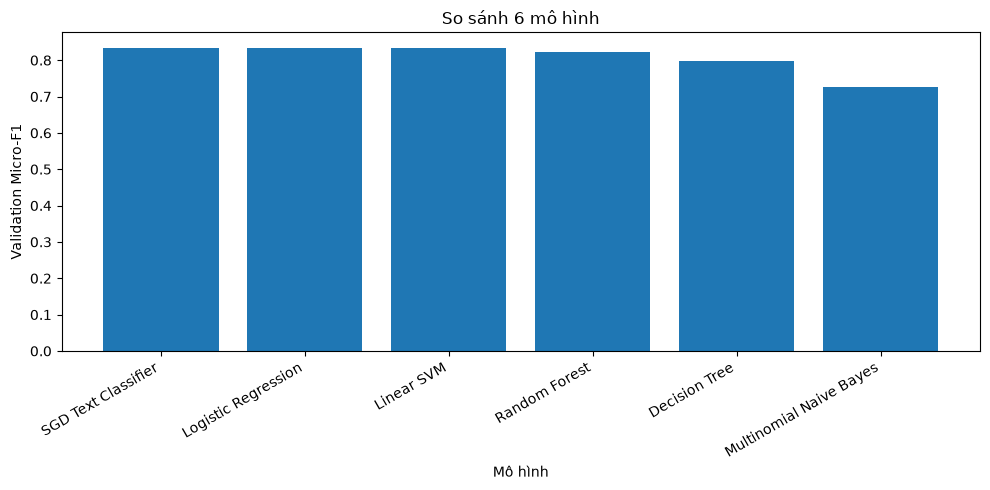

In [24]:
display(
    validation_results.style.format({
        "Subset Accuracy": "{:.4f}",
        "Precision Micro": "{:.4f}",
        "Recall Micro": "{:.4f}",
        "F1 Micro": "{:.4f}",
        "F1 Macro": "{:.4f}",
        "Hamming Loss": "{:.4f}",
        "Jaccard Micro": "{:.4f}",
        "Training Time (s)": "{:.3f}"
    })
)

plt.figure(figsize=(10, 5))

plt.bar(
    validation_results["Model"],
    validation_results["F1 Micro"]
)

plt.ylabel("Validation Micro-F1")
plt.xlabel("Mô hình")
plt.title("So sánh 6 mô hình")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [25]:
best_model_name = (
    validation_results
    .iloc[0]["Model"]
)

best_validation_f1 = (
    validation_results
    .iloc[0]["F1 Micro"]
)

print(
    "Mô hình tốt nhất trên validation:",
    best_model_name
)

print(
    f"Validation Micro-F1: "
    f"{best_validation_f1:.4f}"
)

Mô hình tốt nhất trên validation: SGD Text Classifier
Validation Micro-F1: 0.8350


# 19. Đánh giá mô hình

Sau khi lựa chọn model bằng validation set:

1. gộp training + validation;
2. tạo lại TF-IDF từ dữ liệu training cuối cùng;
3. fit lại model được chọn;
4. đánh giá **một lần** trên test set.

Các metric:

## Precision

$$
Precision =
\frac{TP}{TP+FP}
$$

Trả lời:

> Trong các aspect mà model dự đoán là có đề cập, bao nhiêu dự đoán là đúng?

## Recall

$$
Recall =
\frac{TP}{TP+FN}
$$

Trả lời:

> Trong các aspect thực tế được đề cập, model phát hiện được bao nhiêu?

## F1

$$
F1 =
2
\frac{Precision\times Recall}
{Precision+Recall}
$$

## Hamming Loss

Tỷ lệ label bị dự đoán sai trên toàn bộ:

$$
N\times 8
$$

vị trí label.

Hamming Loss càng thấp càng tốt.

In [26]:
X_train_final = pd.concat([
    X_train,
    X_val
])

y_train_final = pd.concat([
    y_train,
    y_val
])

final_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            **TFIDF_PARAMS
        )
    ),
    (
        "model",
        clone(
            MODEL_ESTIMATORS[
                best_model_name
            ]
        )
    )
])

start = time.perf_counter()

final_model.fit(
    X_train_final,
    y_train_final
)

final_training_time = (
    time.perf_counter()
    - start
)

test_pred = final_model.predict(
    X_test
)

test_metrics = {
    "Selected Model":
        best_model_name,

    "Subset Accuracy":
        accuracy_score(
            y_test,
            test_pred
        ),

    "Precision Micro":
        precision_score(
            y_test,
            test_pred,
            average="micro",
            zero_division=0
        ),

    "Recall Micro":
        recall_score(
            y_test,
            test_pred,
            average="micro",
            zero_division=0
        ),

    "F1 Micro":
        f1_score(
            y_test,
            test_pred,
            average="micro",
            zero_division=0
        ),

    "F1 Macro":
        f1_score(
            y_test,
            test_pred,
            average="macro",
            zero_division=0
        ),

    "Hamming Loss":
        hamming_loss(
            y_test,
            test_pred
        ),

    "Jaccard Micro":
        jaccard_score(
            y_test,
            test_pred,
            average="micro",
            zero_division=0
        ),

    "Final Training Time (s)":
        final_training_time
}

display(
    pd.DataFrame(
        [test_metrics]
    )
)

,Selected Model,Subset Accuracy,Precision Micro,Recall Micro,F1 Micro,F1 Macro,Hamming Loss,Jaccard Micro,Final Training Time (s)
0,SGD Text Classifier,0.528205,0.818158,0.858263,0.837731,0.808117,0.084544,0.720772,1.841653


In [27]:
# Báo cáo theo từng aspect

print(
    classification_report(
        y_test,
        test_pred,
        target_names=ASPECT_COLS,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       Price       0.76      0.82      0.79       287
    Shipping       0.96      0.93      0.94       555
     Outlook       0.94      0.88      0.91       976
     Quality       0.79      0.79      0.79       506
        Size       0.81      0.93      0.87       328
Shop_Service       0.86      0.84      0.85       447
     General       0.56      0.77      0.65       344
      Others       0.55      0.83      0.66       127

   micro avg       0.82      0.86      0.84      3570
   macro avg       0.78      0.85      0.81      3570
weighted avg       0.84      0.86      0.84      3570
 samples avg       0.82      0.86      0.82      3570



In [28]:
# ROC-AUC nếu model hỗ trợ probability hoặc decision score

model_step = final_model.named_steps["model"]

test_scores = None

if hasattr(model_step, "predict_proba"):
    test_scores = (
        model_step.predict_proba(
            final_model
            .named_steps["tfidf"]
            .transform(X_test)
        )
    )

elif hasattr(model_step, "decision_function"):
    test_scores = (
        model_step.decision_function(
            final_model
            .named_steps["tfidf"]
            .transform(X_test)
        )
    )

if test_scores is not None:
    try:
        macro_roc_auc = roc_auc_score(
            y_test,
            test_scores,
            average="macro"
        )

        print(
            f"Macro ROC-AUC: "
            f"{macro_roc_auc:.4f}"
        )

    except ValueError as error:
        print(
            "Không tính được ROC-AUC:",
            error
        )
else:
    print(
        "Model không cung cấp probability/"
        "decision score phù hợp."
    )

Macro ROC-AUC: 0.9551


### Diễn giải kết quả cuối

Trong report cần sử dụng chính các số được notebook tạo ra để trả lời:

- model phát hiện interest tốt đến mức nào;
- Recall có đủ cao để tránh bỏ sót aspect hay không;
- Macro-F1 có thấp hơn Micro-F1 nhiều hay không;
- aspect hiếm nào khó dự đoán;
- lỗi encoding có thể ảnh hưởng kết quả như thế nào.

Không nên chỉ ghi “model có accuracy cao”.

# 20. Phân tích lỗi

Error Analysis cần đi sâu hơn bảng metric.

Các câu hỏi:

1. aspect nào có nhiều False Positive?
2. aspect nào có nhiều False Negative?
3. review nào bị dự đoán sai nhiều label nhất?
4. review ngắn hay dài có khó dự đoán hơn?
5. aspect hiếm có F1 thấp hơn hay không?
6. review chứa nhiều aspect có khó phân loại hơn hay không?

Với multi-label classification, mỗi aspect có một confusion matrix riêng.

In [29]:
# Confusion matrix cho từng aspect

mcm = multilabel_confusion_matrix(
    y_test,
    test_pred
)

confusion_rows = []

for i, aspect in enumerate(ASPECT_COLS):

    tn, fp, fn, tp = (
        mcm[i].ravel()
    )

    confusion_rows.append({
        "Aspect": aspect,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

confusion_table = pd.DataFrame(
    confusion_rows
)

display(confusion_table)

,Aspect,TN,FP,FN,TP
0,Price,1396,72,53,234
1,Shipping,1177,23,38,517
2,Outlook,724,55,116,860
3,Quality,1143,106,104,402
4,Size,1356,71,22,306
5,Shop_Service,1247,61,73,374
6,General,1205,206,79,265
7,Others,1541,87,21,106


,Aspect,Precision,Recall,F1
6,General,0.562633,0.770349,0.650307
7,Others,0.549223,0.834646,0.662500
0,Price,0.764706,0.815331,0.789207
3,Quality,0.791339,0.794466,0.792899
5,Shop_Service,0.859770,0.836689,0.848073
4,Size,0.811671,0.932927,0.868085
2,Outlook,0.939891,0.881148,0.909572
1,Shipping,0.957407,0.931532,0.944292


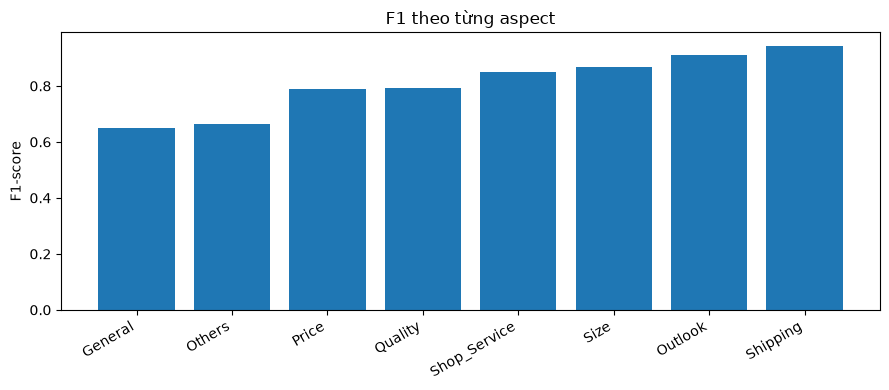

In [30]:
# F1 theo từng aspect

per_aspect_f1 = f1_score(
    y_test,
    test_pred,
    average=None,
    zero_division=0
)

per_aspect_recall = recall_score(
    y_test,
    test_pred,
    average=None,
    zero_division=0
)

per_aspect_precision = precision_score(
    y_test,
    test_pred,
    average=None,
    zero_division=0
)

per_aspect_metrics = pd.DataFrame({
    "Aspect": ASPECT_COLS,
    "Precision": per_aspect_precision,
    "Recall": per_aspect_recall,
    "F1": per_aspect_f1
}).sort_values("F1")

display(per_aspect_metrics)

plt.figure(figsize=(9, 4))

plt.bar(
    per_aspect_metrics["Aspect"],
    per_aspect_metrics["F1"]
)

plt.ylabel("F1-score")
plt.title("F1 theo từng aspect")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [31]:
# Xác định các review sai nhiều label nhất

error_count = (
    y_test.values
    != test_pred
).sum(axis=1)

error_df = pd.DataFrame({
    "Review": X_test.values,
    "So_label_sai": error_count
})

for i, aspect in enumerate(ASPECT_COLS):
    error_df[
        f"Actual_{aspect}"
    ] = y_test.iloc[:, i].values

    error_df[
        f"Pred_{aspect}"
    ] = test_pred[:, i]

display(
    error_df
    .sort_values(
        "So_label_sai",
        ascending=False
    )
    .head(10)
)

,Review,So_label_sai,Actual_Price,Pred_Price,Actual_Shipping,Pred_Shipping,Actual_Outlook,Pred_Outlook,Actual_Quality,Pred_Quality,Actual_Size,Pred_Size,Actual_Shop_Service,Pred_Shop_Service,Actual_General,Pred_General,Actual_Others,Pred_Others
1249,"Size chuan giay dep hy vong mang ben lau, gia phai chang ok dang mua nha giao hang nhanh tot trong tam gia chat luong",5,1,0,1,1,1,0,1,0,1,0,0,0,0,1,0,0
663,"Giao hàng nhanh, giày giống ảnh, đi mềm ncl so với giá thì oke. Còn fom thì hơi nhỏ xíu",5,0,0,0,1,1,0,0,1,0,1,1,0,1,1,0,0
479,Sản phẩm tốt..... Đúng size đúng màu ....giao hàng nhanh ....giá rẽ nên mua nhé mọi người,4,0,1,1,1,1,0,1,0,1,1,0,0,0,1,0,0
1143,Chọn vừa size nên mang rất thoải mái... Giày nhìn sang sáng giá cx ổn... Nói chung là ok lắm đấy,4,1,0,0,0,1,0,0,1,0,1,0,0,1,1,0,0
39,Đi hơi cứng kh ôm chân nma giá như v cũng ổn,4,0,1,0,0,1,0,0,1,0,0,0,0,0,1,0,0
268,Đẹp khuyên đi đúng size giao3hang nhabh có hộp có miếng giữ form không chê đc đi hơi kêu cộp cộp,4,0,0,0,0,0,1,0,0,0,1,0,1,1,0,0,0
334,Mua tặng bố và tâhys bố rất thích Form ổn chắc chân Lâu dài kb ntn nma hiện tại rất hài lòng,4,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,1
34,Bun. GTI gửi Oke sớ ơ đi sidbd. Bởi đi được đạn síbd ke à đi dính sượng.,3,0,0,0,0,0,0,0,1,0,0,0,0,0,1,1,0
859,"Chất liệu với giá tiền như nhau, di cũng ổn , mẫu mã khá ok",3,0,1,0,0,1,0,1,1,0,0,0,0,0,1,0,0
793,Giày tốt xịn lắm nha from to nên bà này thích gọn thì xem xét ạ đi đúng size đi chứ tui sợ bé nên mua hơn 1size về r...,3,0,0,0,0,1,0,1,0,1,1,0,0,0,1,0,0


In [32]:
# Phân tích sai số theo độ dài review

error_length_df = pd.DataFrame({
    "word_count":
        X_test
        .astype(str)
        .str.split()
        .str.len()
        .values,

    "label_errors":
        error_count
})

error_length_df["length_group"] = pd.qcut(
    error_length_df["word_count"],
    q=4,
    duplicates="drop"
)

length_error_summary = (
    error_length_df
    .groupby(
        "length_group",
        observed=True
    )
    .agg(
        so_review=("label_errors", "size"),
        do_dai_trung_binh=("word_count", "mean"),
        so_label_sai_trung_binh=("label_errors", "mean")
    )
)

display(length_error_summary)

,so_review,do_dai_trung_binh,so_label_sai_trung_binh
length_group,,,
"(0.999, 12.0]",488,7.918033,0.526639
"(12.0, 17.0]",453,15.114790,0.653422
"(17.0, 24.0]",380,20.584211,0.757895
"(24.0, 366.0]",434,39.661290,0.797235


### Diễn giải Error Analysis

Nếu một aspect có Recall thấp:

- model đang bỏ sót nhiều review thật sự đề cập aspect đó.

Nếu Precision thấp:

- model đang gán aspect quá nhiều.

Nếu các aspect hiếm có F1 thấp:

- class imbalance là một nguyên nhân khả dĩ.

Nếu review dài hoặc review chứa nhiều aspect có số lỗi lớn hơn:

- cấu trúc câu phức tạp và số lượng chủ đề trong cùng review có thể gây khó khăn cho representation TF-IDF.

Những kết luận này phải dựa trên output thực tế của notebook thay vì suy đoán trước khi chạy model.

# 21. Lựa chọn mô hình

Mô hình cuối cùng được lựa chọn trên **validation set**, không phải test set.

Metric chính:

```text
Micro-F1
```

Các yếu tố bổ sung:

- Macro-F1;
- Precision/Recall;
- Hamming Loss;
- training time;
- khả năng xử lý sparse TF-IDF;
- khả năng lưu và triển khai.

Việc chọn model trước khi đánh giá test giúp tránh **test-set overfitting**.

In [33]:
best_row = (
    validation_results
    .iloc[0]
)

print(
    "Mô hình được chọn:",
    best_model_name
)

print(
    f"Validation Micro-F1: "
    f"{best_row['F1 Micro']:.4f}"
)

print(
    f"Validation Macro-F1: "
    f"{best_row['F1 Macro']:.4f}"
)

print(
    "\nKết quả cuối trên test:"
)

print(
    f"Test Micro-F1: "
    f"{test_metrics['F1 Micro']:.4f}"
)

print(
    f"Test Macro-F1: "
    f"{test_metrics['F1 Macro']:.4f}"
)

print(
    f"Test Hamming Loss: "
    f"{test_metrics['Hamming Loss']:.4f}"
)

Mô hình được chọn: SGD Text Classifier
Validation Micro-F1: 0.8350
Validation Macro-F1: 0.8106

Kết quả cuối trên test:
Test Micro-F1: 0.8377
Test Macro-F1: 0.8081
Test Hamming Loss: 0.0845


### Mẫu giải thích lựa chọn model

Điền tên và các giá trị thực tế từ output:

> Mô hình được lựa chọn để triển khai là **SGD Text Classifier** vì đạt Micro-F1 cao nhất trên tập validation. Micro-F1 được ưu tiên do đây là bài toán multi-label và các aspect bị mất cân bằng. Sau khi lựa chọn model, hệ thống được huấn luyện lại bằng training + validation và chỉ đánh giá một lần trên test set độc lập. Kết quả cuối cùng được đánh giá thêm bằng Macro-F1, Precision, Recall, Hamming Loss và metric theo từng aspect.

# 22. Lưu mô hình

Model cuối cùng phải được lưu để sử dụng lại mà không cần huấn luyện lại.

Pipeline được lưu chứa:

$$
\text{Saved TF-IDF}
+
\text{Saved Multi-label Classification Model}
$$

`TfidfVectorizer` lưu:

- vocabulary;
- vocabulary IDs;
- IDF weights;
- cấu hình n-gram.

Classifier lưu các tham số đã học cho 8 aspect.

Không được thực hiện:

```text
New User Review
        ↓
Fit TfidfVectorizer mới
```

vì feature space khi inference phải giống feature space lúc training.

Hàm `clean_review()` cũng phải được dùng với cùng logic trong Web/API/Mobile.

In [34]:
MODEL_DIR = "model"

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

MODEL_PATH = os.path.join(
    MODEL_DIR,
    "ecommerce_interest_pipeline.joblib"
)

joblib.dump(
    {
        "pipeline": final_model,
        "aspect_names": ASPECT_COLS,
        "target_definition":
            "1 = aspect được đề cập; "
            "0 = aspect không được đề cập",
        "tfidf_params": TFIDF_PARAMS
    },
    MODEL_PATH
)

print(
    "Đã lưu model tại:",
    MODEL_PATH
)

print(
    "File tồn tại:",
    os.path.exists(MODEL_PATH)
)

Đã lưu model tại: model\ecommerce_interest_pipeline.joblib
File tồn tại: True


In [35]:
# Tải lại để kiểm tra persistence

saved_bundle = joblib.load(
    MODEL_PATH
)

loaded_pipeline = (
    saved_bundle["pipeline"]
)

original_predictions = (
    final_model.predict(
        X_test.iloc[:5]
    )
)

reloaded_predictions = (
    loaded_pipeline.predict(
        X_test.iloc[:5]
    )
)

verification = pd.DataFrame({
    "same_prediction": (
        original_predictions
        == reloaded_predictions
    ).all(axis=1)
})

display(verification)

print(
    "Tất cả prediction giống nhau:",
    verification[
        "same_prediction"
    ].all()
)

,same_prediction
0,True
1,True
2,True
3,True
4,True


Tất cả prediction giống nhau: True


# 23. Inference Test

Bước cuối mô phỏng inference của hệ thống triển khai.

$$
\text{Raw Customer Review}
\rightarrow
\text{Text Cleaning}
\rightarrow
\text{Saved TF-IDF}
\rightarrow
\text{Saved Multi-label Model}
\rightarrow
\text{Predicted Interests}
$$

Ví dụ request từ Web/Mobile:

```json
{
  "review": "Giao hàng nhanh, giày đẹp nhưng hơi chật"
}
```

Conceptual response:

```json
{
  "interests": [
    "Shipping",
    "Outlook",
    "Size"
  ]
}
```

Nếu model được chọn hỗ trợ `predict_proba`, API có thể trả thêm probability cho từng interest.

Nếu model chỉ hỗ trợ `decision_function`, có thể trả decision score nhưng không nên gọi trực tiếp đó là probability.

Quan trọng:

> Inference chỉ sử dụng preprocessing và model đã học từ training data. Không fit lại TF-IDF bằng review mới.

In [36]:
# Sử dụng một review thực tế trong dataset để kiểm thử

raw_review = (
    df["Review"]
    .iloc[0]
)

cleaned_review = clean_review(
    raw_review
)

saved_bundle = joblib.load(
    MODEL_PATH
)

deployed_pipeline = (
    saved_bundle["pipeline"]
)

aspect_names = (
    saved_bundle["aspect_names"]
)

prediction = (
    deployed_pipeline
    .predict(
        [cleaned_review]
    )[0]
)

predicted_interests = [
    aspect
    for aspect, value
    in zip(
        aspect_names,
        prediction
    )
    if value == 1
]

print("=" * 70)
print("INFERENCE TEST")
print("=" * 70)

print("\nRAW REVIEW:")
print(raw_review)

print("\nCLEAN REVIEW:")
print(cleaned_review)

print("\nPREDICTED INTERESTS:")
print(predicted_interests)

INFERENCE TEST

RAW REVIEW:
Giày đẹp, đi êm lắm

CLEAN REVIEW:
Giày đẹp, đi êm lắm

PREDICTED INTERESTS:
['Outlook', 'Quality']


In [37]:
def predict_customer_interests(
    raw_review_text,
    model_path=MODEL_PATH
):
    # 1. Làm sạch đúng logic khi training
    cleaned_text = clean_review(
        raw_review_text
    )

    # 2. Tải model đã lưu
    bundle = joblib.load(
        model_path
    )

    pipeline = bundle["pipeline"]
    aspects = bundle["aspect_names"]

    # 3. Prediction
    pred = pipeline.predict(
        [cleaned_text]
    )[0]

    interests = [
        aspect
        for aspect, value
        in zip(aspects, pred)
        if value == 1
    ]

    result = {
        "review": raw_review_text,
        "interests": interests
    }

    # 4. Probability nếu model hỗ trợ
    model_step = (
        pipeline
        .named_steps["model"]
    )

    if hasattr(
        model_step,
        "predict_proba"
    ):
        transformed = (
            pipeline
            .named_steps["tfidf"]
            .transform(
                [cleaned_text]
            )
        )

        probabilities = (
            model_step
            .predict_proba(
                transformed
            )[0]
        )

        result["scores"] = {
            aspect:
                round(
                    float(score),
                    4
                )
            for aspect, score
            in zip(
                aspects,
                probabilities
            )
        }

    return result


example_review = (
    df["Review"]
    .iloc[1]
)

example_response = (
    predict_customer_interests(
        example_review
    )
)

print(example_response)

{'review': 'Mình săn sale với giá khá rẻ Chất lượng ok Shipper thân thiện Sẽ tiếp tục ủng hộ shop', 'interests': ['Price', 'Shipping', 'Quality'], 'scores': {'Price': 0.9918, 'Shipping': 0.7775, 'Outlook': 0.1643, 'Quality': 0.8499, 'Size': 0.0783, 'Shop_Service': 0.1446, 'General': 0.2816, 'Others': 0.1019}}


### Complete Intelligent-System Pipeline

$$
\text{Vietnamese Customer Review}
\rightarrow
\text{Clean}
\rightarrow
\text{Represent}
\rightarrow
\text{TF-IDF}
\rightarrow
\text{Learn}
\rightarrow
\text{Evaluate}
\rightarrow
\text{Persist}
\rightarrow
\text{Inference}
$$

### Input Representation

$$
X \in \mathbb{R}^{N\times d}
$$

Trong đó:

- $N$: số review;
- $d$: số feature TF-IDF.

### Target Representation

Với một review:

$$
\mathbf{y}_i =
[y_{i1},y_{i2},\ldots,y_{i8}]
$$

Với toàn bộ dataset:

$$
Y \in \{0,1\}^{N\times8}
$$

8 target columns:

$$
[
Price,\ Shipping,\ Outlook,\ Quality,\ Size,\ Shop\_Service,\ General,\ Others
]
$$